# Analyse de Reproductibilité StarTrek

Ce notebook permet de vérifier la reproductibilité des résultats d'entraînement en utilisant 5 seeds différentes. Il génère un rapport statistique incluant la moyenne et l'intervalle de confiance à 95 %.

## 1. Importations et Configuration

In [ ]:
import subprocess
import re
import math
import matplotlib.pyplot as plt
import sys
import os
import time

SEEDS = [89, 67, 69, 62, 99]
CONFIG = "configs/exp_fast.yaml"
TRAIN_SCRIPT = "train.py"

def get_total_episodes(config_path):
    try:
        path = f"../{config_path}" if not os.path.exists(config_path) else config_path
        with open(path, "r") as f:
            content = f.read()
            match = re.search(r"episodes:\s*(\d+)", content)
            if match:
                return int(match.group(1))
    except Exception:
        pass
    return 100

def run_training(seed):
    print(f"[*] Lancement de l'entraînement avec la seed {seed}...")
    total_episodes = get_total_episodes(CONFIG)
    
    process = subprocess.Popen(
        [sys.executable, TRAIN_SCRIPT, CONFIG, str(seed)],
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        cwd="..",
        bufsize=1
    )
    
    scores = []
    start_time = time.time()
    
    for line in iter(process.stdout.readline, ""):
        line = line.strip()
        if not line:
            continue
            
        print(line)
        match = re.search(r"Score:\s*([\d\.-]+)", line)
        if match:
            try:
                scores.append(float(match.group(1)))
                
                # Calcul et affichage de l'ETA pour la seed en cours
                episodes_done = len(scores)
                elapsed = time.time() - start_time
                avg_time_per_ep = elapsed / episodes_done
                episodes_left = total_episodes - episodes_done
                eta_seconds = max(0, avg_time_per_ep * episodes_left)
                
                eta_str = time.strftime("%H:%M:%S", time.gmtime(eta_seconds))
                print(f"    -> [ETA pour la fin de la seed {seed} : {eta_str}]")
            except Exception:
                pass

    process.stdout.close()
    process.wait()

    if process.returncode != 0:
        print(f"[!] L'entraînement a échoué avec le code {process.returncode}")
        
    return scores

## 2. Exécution des Sessions d'Entraînement

Cette étape peut prendre plusieurs minutes selon le nombre d'épisodes configurés.

In [6]:
import time

results = {}
start_time_total = time.time()

for i, seed in enumerate(SEEDS):
    start_time_seed = time.time()
    results[seed] = run_training(seed)
    end_time_seed = time.time()
    
    # Calcul des temps
    elapsed_seed = end_time_seed - start_time_seed
    elapsed_total = end_time_seed - start_time_total
    
    # Estimation du temps restant
    seeds_done = i + 1
    seeds_left = len(SEEDS) - seeds_done
    avg_time_per_seed = elapsed_total / seeds_done
    eta_seconds = avg_time_per_seed * seeds_left
    
    eta_str = time.strftime("%H:%M:%S", time.gmtime(eta_seconds))
    print(f"[-] Seed {seed} terminée en {elapsed_seed:.2f}s. ETA pour les seeds restantes : {eta_str}\n")


[*] Lancement de l'entraînement avec la seed 89...
<frozen importlib._bootstrap>:491: RuntimeWarning: Your system is avx2 capable but pygame was not built with support for it. The performance of some of your blits could be adversely affected. Consider enabling compile time detection with environment variables like PYGAME_DETECT_AVX2=1 if you are compiling without cross compilation.
/home/crabe/Dev/Epitech/AIA-400/G-AIA-401-LIL-4-1-starttrek-4/.venv/lib/python3.14/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
from pkg_resources import resource_stream, resource_exists
/home/crabe/Dev/Epitech/AIA-400/G-AIA-401-LIL-4-1-starttrek-4/src/agent.py:31: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list 

## 3. Analyse Statistique et Visualisation

Calcul de la moyenne et de l'intervalle de confiance (95%) sans bibliothèques tierces.

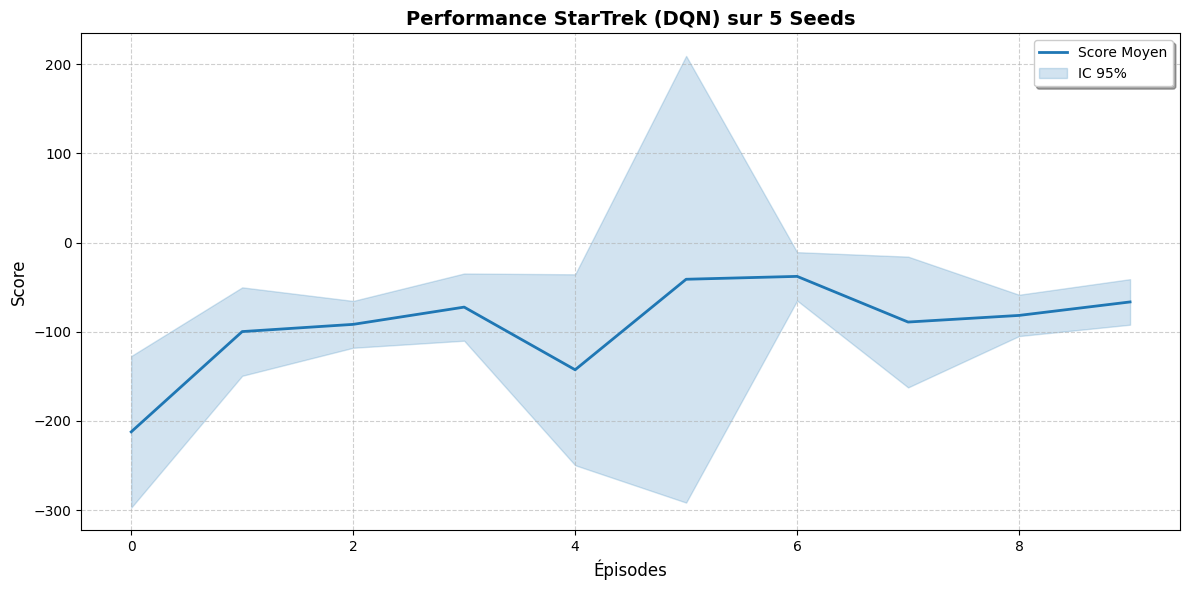

In [ ]:
all_runs = [results[s] for s in SEEDS if len(results[s]) > 0]

if not all_runs:
    print("[!] Erreur : Aucun score n'a été collecté. Vérifiez que l'entraînement s'est bien déroulé.")
else:
    min_len = min(len(r) for r in all_runs)
    all_runs_trimmed = [r[:min_len] for r in all_runs]
    n = len(all_runs_trimmed)

    mean_curve = []
    for i in range(min_len):
        val_at_i = [run[i] for run in all_runs_trimmed]
        mean_curve.append(sum(val_at_i) / n)

    ci_curve = []
    t_value = 2.776
    if n < 5:
        t_map = {1: 12.706, 2: 4.303, 3: 3.182, 4: 2.776}
        t_value = t_map.get(n-1, 2.0)

    for i in range(min_len):
        val_at_i = [run[i] for run in all_runs_trimmed]
        m = mean_curve[i]
        variance = sum((x - m)**2 for x in val_at_i) / (n - 1) if n > 1 else 0
        std_dev = math.sqrt(variance)
        std_error = std_dev / math.sqrt(n)
        ci_curve.append(t_value * std_error)

    plt.figure(figsize=(12, 6))
    episodes = list(range(min_len))
    plt.plot(episodes, mean_curve, color='#1f77b4', label='Score Moyen', linewidth=2)

    lower_bound = [m - c for m, c in zip(mean_curve, ci_curve)]
    upper_bound = [m + c for m, c in zip(mean_curve, ci_curve)]

    plt.fill_between(episodes, lower_bound, upper_bound, color='#1f77b4', alpha=0.2, label='IC 95%')

    plt.title(f'Performance StarTrek (DQN) sur {n} Seeds', fontsize=14, fontweight='bold')
    plt.xlabel('Épisodes', fontsize=12)
    plt.ylabel('Score', fontsize=12)
    plt.legend(frameon=True, shadow=True)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

In [8]:
print(all_runs)

[[-270.15, -145.38, -93.5, -82.86, -87.63, 267.77, -63.51, -119.15, -90.48, -87.32], [-301.07, -99.61, -55.78, -58.79, -269.08, -18.13, -39.74, -60.45, -52.52, -62.52], [-158.17, -43.16, -100.23, -82.53, -77.65, -287.67, -45.35, -10.22, -93.66, -37.85], [-153.52, -82.76, -111.41, -109.26, -196.45, -48.66, -37.69, -166.66, -97.89, -59.42], [-178.5, -128.2, -97.73, -28.44, -82.49, -119.04, -3.27, -89.14, -73.92, -85.8]]


## 4. Rapport de Performance Final

Moyenne sur les 100 derniers épisodes (ou moins si l'entraînement est court) pour chaque seed.

In [ ]:
if not all_runs:
    print("[!] Aucun rapport final possible.")
else:
    final_performances = []
    for run in all_runs:
        # On prend les 100 derniers épisodes
        window = min(100, len(run))
        last_window = run[-window:]
        if last_window:
            final_performances.append(sum(last_window) / len(last_window))

    if final_performances:
        n_final = len(final_performances)
        final_mean = sum(final_performances) / n_final
        final_variance = sum((x - final_mean)**2 for x in final_performances) / (n_final - 1) if n_final > 1 else 0
        final_std_error = math.sqrt(final_variance) / math.sqrt(n_final)
        
        t_map = {1: 12.706, 2: 4.303, 3: 3.182, 4: 2.776}
        t_val = t_map.get(n_final-1, 2.0)
        final_ci = t_val * final_std_error

        print("="*40)
        print(" RAPPORT DE REPRODUCTIBILITÉ ")
        print("="*40)
        print(f"Configuration : {CONFIG}")
        print(f"Runs réussis : {n_final}/{len(SEEDS)}")
        print(f"Performance Finale : {final_mean:.2f} ± {final_ci:.2f}")
        print("="*40)
    else:
        print("[!] Pas assez de données pour le rapport final.")

 RAPPORT DE REPRODUCTIBILITÉ 
Configuration : configs/exp_fast.yaml
Runs réussis : 5/5
Performance Finale : -93.53 ± 14.19
